# 02 - Language & Integration

Analyze Korean-language proficiency, length of stay, belonging, and integration variables.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
import seaborn as sns

from sklearn.model_selection import KFold, cross_validate

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.svm import SVR, SVC

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

In [3]:
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "seoul_foreigners_modeling_master.csv"

TRAIN_PATH = PROJECT_ROOT / "data" / "processed" / "train_ids.csv"

TEST_PATH = PROJECT_ROOT / "data" / "processed" / "test_ids.csv"

In [4]:
df = pd.read_csv(DATA_PATH)

train_ids = pd.read_csv(TRAIN_PATH)

test_ids = pd.read_csv(TEST_PATH)

print(df.shape)

df.head()

(2500, 165)


,ID,AREA,SQ1,SQ1_1,SQ2,SQ2_1,SQ2_1_1,SQ3,SQ4_1,SQ4_2,...,RIM_WT,RIM_WT1,high_satisfaction,age,months_in_korea,korean_proficiency_mean,korean_proficiency_10,months_in_korea_log1p,SQ6_1_log1p,SQ6_2_log1p
0,1,10,9,904,2,2,NaN,1990,5,9,...,29.205606,0.194471,0,35,69,2.0,2.50,4.248495,7.601402,4.262680
1,2,10,6,609,1,2,NaN,2000,1,0,...,28.202208,0.187790,0,25,12,3.0,5.00,2.564949,6.908755,4.110874
2,3,10,9,901,2,2,NaN,1979,14,5,...,52.991877,0.352857,1,46,173,2.5,3.75,5.159055,NaN,NaN
3,4,10,7,7,2,2,NaN,1991,3,5,...,44.217196,0.294429,1,34,41,3.5,6.25,3.737670,7.601402,4.394449
4,5,10,6,619,1,2,NaN,1985,0,9,...,59.107090,0.393576,0,40,9,2.5,3.75,2.302585,4.615121,3.713572


In [6]:
df.columns.tolist()

['ID',
 'AREA',
 'SQ1',
 'SQ1_1',
 'SQ2',
 'SQ2_1',
 'SQ2_1_1',
 'SQ3',
 'SQ4_1',
 'SQ4_2',
 'SQ5',
 'SQ6',
 'SQ6_1',
 'SQ6_2',
 'SQ7',
 'SQ8',
 'Q1_1',
 'Q1_2',
 'Q1_3',
 'Q1_4',
 'Q2',
 'Q2_1',
 'Q3',
 'Q3_1',
 'Q4_1',
 'Q4_2',
 'Q4_3',
 'Q4_4',
 'Q4_5',
 'Q4_6',
 'Q4_7',
 'Q5',
 'Q6_1',
 'Q6_2',
 'Q6_3',
 'Q6_4',
 'Q6_5',
 'Q6_6',
 'Q6_7',
 'Q6_8',
 'Q6_9',
 'Q6_10',
 'Q6_11',
 'Q6_12',
 'Q7_1',
 'Q7_2',
 'Q7_3',
 'Q7_4',
 'Q7_5',
 'Q7_6',
 'Q7_7',
 'Q8_1',
 'Q8_2',
 'Q9_1',
 'Q9_2',
 'Q9_3',
 'Q9_4',
 'Q9_5',
 'Q10_1',
 'Q10_2',
 'Q10_3',
 'Q10_4',
 'Q10_5',
 'Q11',
 'Q12',
 'Q13_1',
 'Q13_2',
 'Q13_3',
 'Q13_4',
 'Q13_5',
 'Q13_6',
 'Q13_7',
 'Q13_8',
 'Q14',
 'Q14_1',
 'Q15',
 'Q16',
 'Q16_1',
 'Q17_1',
 'Q17_2',
 'Q17_3',
 'Q17_4',
 'Q18',
 'Q19_1',
 'Q19_2',
 'Q19_3',
 'Q19_4',
 'Q20_1',
 'Q20_2',
 'Q20_3',
 'Q20_4',
 'Q21_1',
 'Q21_2',
 'Q21_3',
 'Q21_4',
 'Q21_5',
 'Q21_6',
 'Q21_7',
 'Q22_1',
 'Q22_2',
 'Q22_3',
 'Q22_4',
 'Q23_1_1',
 'Q23_1_2',
 'Q23_1_3',
 'Q23_1_4',
 'Q23

## 2. Select Features

In [7]:
features = [
    "korean_proficiency_10",
    "months_in_korea",
    "age"
]

target_reg = "Q11"

target_cls = "high_satisfaction"

selected_df = df[features + [target_reg, target_cls]]

selected_df.head()

,korean_proficiency_10,months_in_korea,age,Q11,high_satisfaction
0,2.50,69,35,7,0
1,5.00,12,25,6,0
2,3.75,173,46,8,1
3,6.25,41,34,9,1
4,3.75,9,40,7,0


## 3. Missing Value Analysis

In [8]:
selected_df.isnull().sum()

korean_proficiency_10    0
months_in_korea          0
age                      0
Q11                      0
high_satisfaction        0
dtype: int64

In [9]:
selected_df.describe()

,korean_proficiency_10,months_in_korea,age,Q11,high_satisfaction
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,6.482750,58.253600,34.279200,7.768400,0.655200
std,2.274435,59.316944,10.302024,1.130696,0.475398
min,0.000000,3.000000,20.000000,0.000000,0.000000
25%,5.000000,15.000000,26.000000,7.000000,0.000000
50%,6.875000,36.000000,33.000000,8.000000,1.000000
75%,8.125000,84.000000,40.000000,8.000000,1.000000
max,10.000000,492.000000,84.000000,10.000000,1.000000


## 4. Exploratory Data Analysis (EDA)

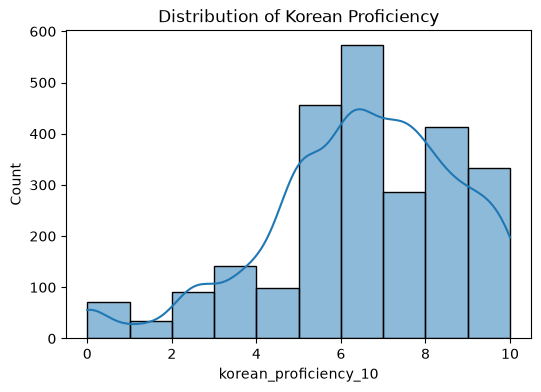

In [10]:
plt.figure(figsize=(6,4))

sns.histplot(
    df["korean_proficiency_10"],
    bins=10,
    kde=True
)

plt.title("Distribution of Korean Proficiency")

plt.show()

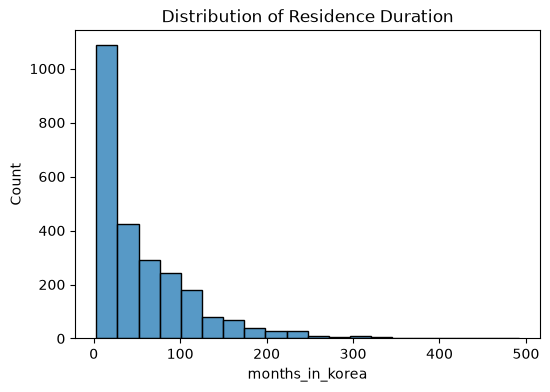

In [11]:
plt.figure(figsize=(6,4))

sns.histplot(
    df["months_in_korea"],
    bins=20
)

plt.title("Distribution of Residence Duration")

plt.show()

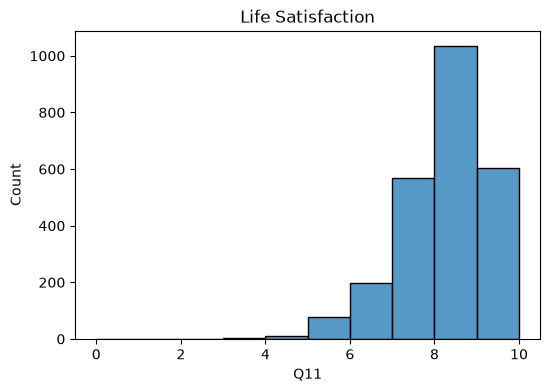

In [12]:
plt.figure(figsize=(6,4))

sns.histplot(
    df["Q11"],
    bins=10
)

plt.title("Life Satisfaction")

plt.show()

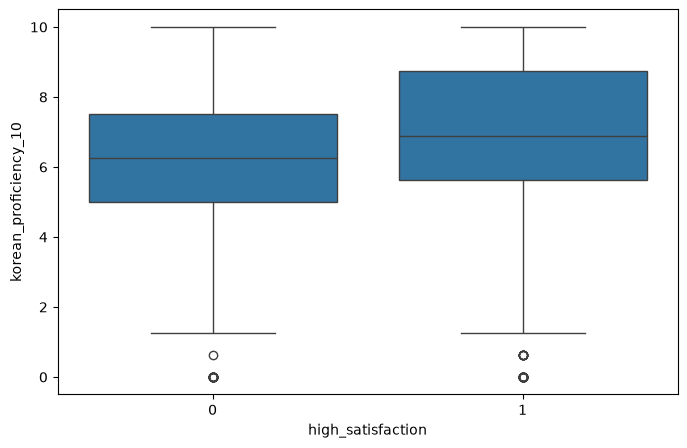

In [13]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x="high_satisfaction",
    y="korean_proficiency_10",
    data=df
)

plt.show()

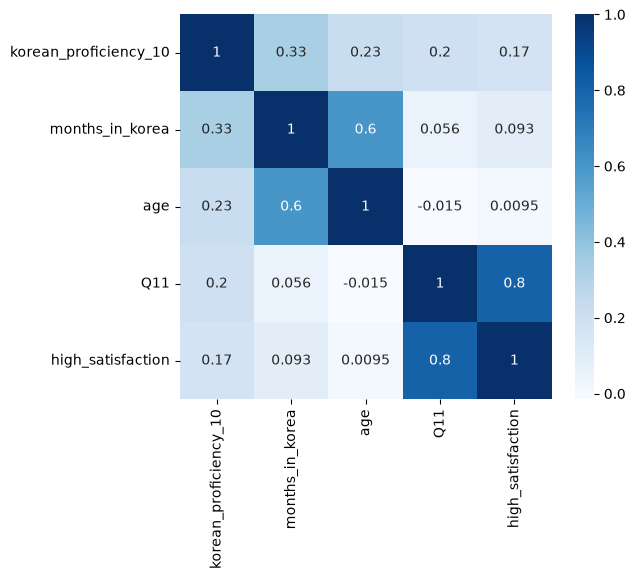

In [14]:
plt.figure(figsize=(6,5))

sns.heatmap(
    selected_df.corr(numeric_only=True),
    annot=True,
    cmap="Blues"
)

plt.show()

## 5. Train/Test Split

In [15]:
train_ids.head()

,ID
0,1013
1,2097
2,2031
3,1282
4,1336


In [16]:
test_ids.head()

,ID
0,359
1,2084
2,64
3,413
4,174


## 5. Train/Test Split
Use the predefined train and test IDs generated in Notebook 01.

In [17]:
train_df = df[df["ID"].isin(train_ids["ID"])].copy()
test_df = df[df["ID"].isin(test_ids["ID"])].copy()

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Train shape: (2000, 165)
Test shape: (500, 165)


In [18]:
X_train = train_df[features]
X_test = test_df[features]

y_train_reg = train_df[target_reg]
y_test_reg = test_df[target_reg]

y_train_cls = train_df[target_cls]
y_test_cls = test_df[target_cls]

## 6. Regression

In [19]:
lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

lr.fit(X_train, y_train_reg)

pred_lr = lr.predict(X_test)

print("Linear Regression")
print("MAE :", mean_absolute_error(y_test_reg, pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test_reg, pred_lr)))
print("R²  :", r2_score(y_test_reg, pred_lr))

Linear Regression
MAE : 0.8194353448827785
RMSE: 1.1295501396816823
R²  : 0.015874318103003437


In [20]:
svr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVR())
])

svr.fit(X_train, y_train_reg)

pred_svr = svr.predict(X_test)

print("SVR")
print("MAE :", mean_absolute_error(y_test_reg, pred_svr))
print("RMSE:", np.sqrt(mean_squared_error(y_test_reg, pred_svr)))
print("R²  :", r2_score(y_test_reg, pred_svr))

SVR
MAE : 0.7591692358302512
RMSE: 1.110040451968186
R²  : 0.0495765366367793


In [21]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    lr,
    X_train,
    y_train_reg,
    cv=cv,
    scoring=("neg_mean_absolute_error", "r2")
)

print("Mean MAE:", -scores["test_neg_mean_absolute_error"].mean())
print("Mean R² :", scores["test_r2"].mean())

Mean MAE: 0.8329792156244477
Mean R² : 0.04292211602754174


## 7. Classification

In [22]:
log_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

log_model.fit(X_train, y_train_cls)

pred = log_model.predict(X_test)
prob = log_model.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test_cls, pred))
print("Precision:", precision_score(y_test_cls, pred))
print("Recall   :", recall_score(y_test_cls, pred))
print("F1 Score :", f1_score(y_test_cls, pred))
print("ROC-AUC  :", roc_auc_score(y_test_cls, prob))

Accuracy : 0.656
Precision: 0.6638655462184874
Recall   : 0.9634146341463414
F1 Score : 0.7860696517412935
ROC-AUC  : 0.6074074730572887


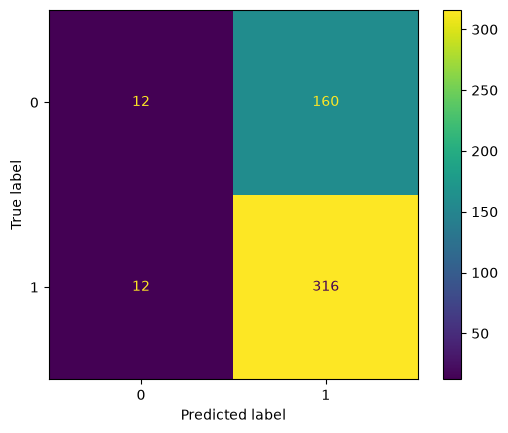

In [23]:
cm = confusion_matrix(y_test_cls, pred)

ConfusionMatrixDisplay(cm).plot()

plt.show()

In [24]:
svm = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(probability=True))
])

svm.fit(X_train, y_train_cls)

pred = svm.predict(X_test)
prob = svm.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test_cls, pred))
print("Precision:", precision_score(y_test_cls, pred))
print("Recall   :", recall_score(y_test_cls, pred))
print("F1 Score :", f1_score(y_test_cls, pred))
print("ROC-AUC  :", roc_auc_score(y_test_cls, prob))

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Accuracy : 0.668
Precision: 0.6666666666666666
Recall   : 0.9878048780487805
F1 Score : 0.7960687960687961
ROC-AUC  : 0.6157738939307997
